In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
df = pd.read_csv("titanic.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
TARGET = "Survived"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' not found."
    )

print("Missing values:")
display(df.isnull().sum())

print("Target distribution:")
display(df[TARGET].value_counts())

print("Target percentages:")
display(df[TARGET].value_counts(normalize=True) * 100)

print("Duplicate rows:", df.duplicated().sum())

Missing values:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Target distribution:


Survived
0    549
1    342
Name: count, dtype: int64

Target percentages:


Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

Duplicate rows: 0


In [7]:
df = df.dropna(subset=[TARGET]).copy()
df = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (891, 12)


In [8]:
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# Remove identifiers that should not be used
# as predictive features.
identifier_columns = [
    col for col in ["PassengerId", "Name", "Ticket"]
    if col in X.columns
]

X = X.drop(columns=identifier_columns)

# Remove columns containing no useful variation.
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_columns)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Features:", X.columns.tolist())

Feature shape: (891, 8)
Target shape: (891,)
Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin', 'Embarked']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [10]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)




Numerical features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Sex', 'Cabin', 'Embarked']


In [11]:
models = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        "params": {
            "classifier__C": [0.1, 1, 10],
            "classifier__solver": ["lbfgs"]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "params": {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 10],
            "classifier__min_samples_leaf": [1, 2]
        }
    },

    "Support Vector Machine": {
        "model": SVC(
            probability=True,
            random_state=RANDOM_STATE
        ),
        "params": {
            "classifier__C": [0.1, 1, 10],
            "classifier__kernel": ["rbf", "linear"]
        }
    },

    "Gradient Boosting": {
        "model": HistGradientBoostingClassifier(
            random_state=RANDOM_STATE
        ),
        "params": {
            "classifier__learning_rate": [0.05, 0.1],
            "classifier__max_iter": [100, 200],
            "classifier__max_leaf_nodes": [15, 31]
        }
    }
}

print("Total model architectures:", len(models))

Total model architectures: 4


In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation folds:", cv.get_n_splits())

Cross-validation folds: 5


In [13]:
best_models = {}
comparison_results = []

for name, config in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", config["model"])
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_

    comparison_results.append({
        "Model": name,
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": str(grid_search.best_params_)
    })

    print("Best CV ROC-AUC:", grid_search.best_score_)
    print("Best Parameters:", grid_search.best_params_)


Training: Logistic Regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best CV ROC-AUC: 0.8596964287599084
Best Parameters: {'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}

Training: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV ROC-AUC: 0.8759827902852979
Best Parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Training: Support Vector Machine
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV ROC-AUC: 0.862571047465248
Best Parameters: {'classifier__C': 0.1, 'classifier__kernel': 'rbf'}

Training: Gradient Boosting
Fitting 5 folds for each of 8 candidates, totalling 40 fits


ValueError: 
All the 40 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\pipeline.py", line 649, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\base.py",

In [23]:
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

comparison_df.to_csv(
    "outputs/model_tuning_results.csv",
    index=False
)

print("Model tuning results saved successfully!")

,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.859696,"{'classifier__C': 0.1, 'classifier__solver': '..."
1,Random Forest,0.875983,"{'classifier__max_depth': None, 'classifier__m..."
2,Support Vector Machine,0.862571,"{'classifier__C': 0.1, 'classifier__kernel': '..."


Model tuning results saved successfully!


In [14]:
print("Number of trained models:", len(best_models))
print("Model names:", list(best_models.keys()))

Number of trained models: 3
Model names: ['Logistic Regression', 'Random Forest', 'Support Vector Machine']


In [15]:
evaluation_results = []

for name, model in best_models.items():

    print("Evaluating:", name)

    y_pred = model.predict(X_test)

    # Get probability of the positive class (Survived = 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: Support Vector Machine


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Support Vector Machine,0.8045,0.7833,0.6812,0.7287,0.8477
1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8445
2,Random Forest,0.8045,0.8864,0.5652,0.6903,0.8333


In [27]:
print(evaluation_results)

[{'Model': 'Logistic Regression', 'Accuracy': 0.8044692737430168, 'Precision': 0.7833333333333333, 'Recall': 0.6811594202898551, 'F1-Score': 0.7286821705426356, 'ROC-AUC': 0.8445322793148881}, {'Model': 'Random Forest', 'Accuracy': 0.8044692737430168, 'Precision': 0.8863636363636364, 'Recall': 0.5652173913043478, 'F1-Score': 0.6902654867256637, 'ROC-AUC': 0.8333333333333334}, {'Model': 'Support Vector Machine', 'Accuracy': 0.8044692737430168, 'Precision': 0.7833333333333333, 'Recall': 0.6811594202898551, 'F1-Score': 0.7286821705426356, 'ROC-AUC': 0.8476943346508564}]


In [28]:
results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Support Vector Machine,0.8045,0.7833,0.6812,0.7287,0.8477
1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8445
2,Random Forest,0.8045,0.8864,0.5652,0.6903,0.8333


In [29]:
import os

os.makedirs("outputs", exist_ok=True)

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("model_comparison.csv created successfully!")

model_comparison.csv created successfully!


In [16]:
results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Model comparison table saved.")

Model comparison table saved.


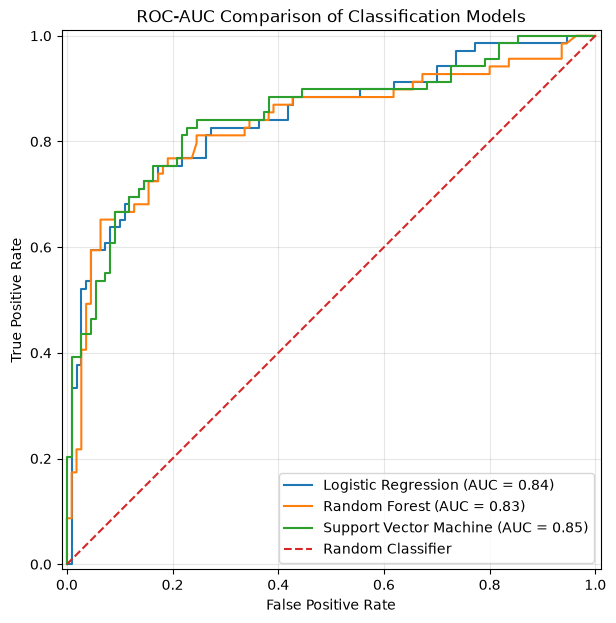

In [17]:
plt.figure(figsize=(10, 7))

ax = plt.gca()

for name, model in best_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC-AUC Comparison of Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.savefig(
    "outputs/roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
print("CHAMPION MODEL:", champion_name)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Did not survive", "Survived"],
        zero_division=0
    )
)

print("\nChampion model parameters:")

print(champion_model.named_steps["classifier"])

CHAMPION MODEL: Support Vector Machine

Classification Report:
                 precision    recall  f1-score   support

Did not survive       0.82      0.88      0.85       110
       Survived       0.78      0.68      0.73        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179


Champion model parameters:
SVC(C=0.1, probability=True, random_state=42)


In [32]:
import joblib
import os

os.makedirs("outputs", exist_ok=True)

joblib.dump(
    champion_model,
    "outputs/champion_model.joblib"
)

print("Champion model saved successfully!")

Champion model saved successfully!


In [33]:
for file in os.listdir("outputs"):
    print("✅", file)

✅ .ipynb_checkpoints
✅ champion_model.joblib
✅ confusion_matrix.png
✅ model_comparison.csv
✅ model_tuning_results.csv
✅ roc_auc_comparison.png


## Conclusion

In this project, four supervised classification algorithms were trained and compared using the Titanic dataset to predict passenger survival. The models were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. Hyperparameter tuning was performed using GridSearchCV with stratified 5-fold cross-validation to improve model performance.

The best-performing model was selected based on its cross-validation ROC-AUC score. The project also generated a model comparison table, ROC-AUC curves, and a confusion matrix to analyze the classification results. Finally, the selected champion model was saved as a Joblib file for future predictions.

This project demonstrates the complete machine learning workflow, from data preprocessing and model training to evaluation, model selection, and serialization.